# CEJ-Based Bone Level Estimation — Improved Pipeline
## Dental AI — Exploratory Clinical Extension (v2)

---

### What Changed From v1
| Component | v1 (15% agreement) | v2 (this notebook) |
|-----------|-------------------|--------------------|
| Preprocessing | Raw grayscale | CLAHE + Gaussian smoothing |
| CEJ detection | Single vertical profile | Column-wise gradient → median |
| Apex detection | Background threshold | Column-wise last tooth signal → median |
| Bone crest | Left/right lateral comparison | Focused search (CEJ to CEJ+40% root), column-wise, outlier filtered |
| Confidence | None (always outputs) | Variance-based reliability scoring |
| Region isolation | None | Top/bottom 10% trimmed, tooth band detection |

### Pipeline
```
1. Preprocess (CLAHE + smoothing)
2. Isolate tooth region (trim edges, find tooth band)
3. Column-wise CEJ detection (median of gradient peaks)
4. Column-wise apex detection (median of bottom boundaries)
5. Bone crest detection (focused near CEJ, per-column, IQR filtered)
6. Compute: bone_loss_% = (crest - CEJ) / (apex - CEJ)
7. Confidence filtering (unreliable cases flagged)
8. Map to severity: <33% mild, 33-50% moderate, >50% severe
```

---
## Cell 1 — Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter1d
from collections import Counter

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Imports loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Imports loaded.


In [2]:
# =============================================================================
# PATHS
# =============================================================================
SEVERITY_DIR = "/content/drive/MyDrive/tufts/severity_dataset"
# Fallback: use processed_dataset_tufts if severity_dataset doesn't exist
SOURCE_DATASET = "/content/drive/MyDrive/tufts/processed_dataset_tufts"
MODEL_DIR = "/content/drive/MyDrive/tufts/models"

# =============================================================================
# CEJ CONFIG
# =============================================================================
# Step 1 — Region isolation
TRIM_TOP_FRAC    = 0.10   # Ignore top 10% (air/background)
TRIM_BOTTOM_FRAC = 0.10   # Ignore bottom 10% (background)
CENTER_BAND_FRAC = 0.60   # Use central 60% of columns for analysis

# Step 2 — CEJ detection
CEJ_SEARCH_UPPER = 0.60   # Search for CEJ in top 60% of trimmed region

# Step 3 — Apex detection
APEX_BG_PERCENTILE = 20   # Background intensity threshold percentile

# Step 4 — Bone crest
CREST_SEARCH_FRAC = 0.40  # Search within CEJ to CEJ + 40% of root length
IQR_MULTIPLIER    = 1.5   # For outlier removal

# Step 6 — Confidence
CEJ_VARIANCE_THRESHOLD   = 25.0   # Max std of CEJ column estimates (pixels)
MIN_VALID_CREST_POINTS   = 3      # Minimum crest detections required
MIN_ROOT_LENGTH_PX       = 15     # Minimum root length in pixels

# Step 7 — Severity
MILD_THRESHOLD     = 33.0
MODERATE_THRESHOLD = 50.0

# Preprocessing
CLAHE_CLIP   = 2.0
CLAHE_GRID   = 8
GAUSS_SIGMA  = 1.5

os.makedirs(MODEL_DIR, exist_ok=True)
print("Config loaded.")

Config loaded.


---
## Cell 2 — STEP 1: Preprocessing + Tooth Region Isolation

In [3]:
def preprocess_crop(crop_gray):
    """
    CLAHE contrast enhancement + Gaussian smoothing.

    CLAHE: Adaptive histogram equalization — normalizes local contrast
    across the crop, making bone/tooth/background boundaries more visible.
    Critical for OPG crops where exposure varies across the image.
    """
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=(CLAHE_GRID, CLAHE_GRID))
    enhanced = clahe.apply(crop_gray)

    # Gentle Gaussian smoothing to reduce pixel noise without killing edges
    smoothed = cv2.GaussianBlur(enhanced, (0, 0), GAUSS_SIGMA)

    return smoothed


def isolate_tooth_region(crop):
    """
    STEP 1 — Isolate the tooth band.

    - Trim top 10% (air/background above teeth)
    - Trim bottom 10% (background below roots)
    - Return the trimmed region boundaries

    This prevents false CEJ/apex detections at crop edges.
    """
    h, w = crop.shape[:2]

    y_start = int(h * TRIM_TOP_FRAC)
    y_end = int(h * (1.0 - TRIM_BOTTOM_FRAC))

    # Column margins
    x_margin = int(w * (1.0 - CENTER_BAND_FRAC) / 2)
    x_start = x_margin
    x_end = w - x_margin

    return y_start, y_end, x_start, x_end


print("Preprocessing functions defined.")

Preprocessing functions defined.


---
## Cell 3 — STEP 2: Column-Wise CEJ Detection

In [4]:
def detect_cej_columnwise(crop, y_start, y_end, x_start, x_end):
    """
    STEP 2 — Column-wise CEJ detection.

    For each column in the central band:
      1. Extract vertical intensity profile
      2. Smooth with Savitzky-Golay
      3. Compute gradient
      4. Find strongest negative gradient in upper region = CEJ

    Final CEJ = median across all columns.

    WHY column-wise:
      - Robust to noise (single bad column doesn't ruin estimate)
      - Handles tilted teeth (CEJ isn't at same height across columns)
      - Median ignores outlier columns

    Returns: (cej_y, cej_std, cej_per_column)
    """
    h = y_end - y_start
    search_limit = y_start + int(h * CEJ_SEARCH_UPPER)

    cej_estimates = []

    # Savgol window must be odd and <= data length
    win = min(15, h // 2 * 2 - 1)
    if win < 5:
        win = 5
    if win % 2 == 0:
        win += 1

    for col in range(x_start, x_end):
        profile = crop[y_start:y_end, col].astype(float)

        if len(profile) < win:
            continue

        # Smooth
        smoothed = savgol_filter(profile, window_length=win, polyorder=3)

        # Gradient
        gradient = np.gradient(smoothed)

        # Search in upper region for strongest negative gradient
        # (crown = bright enamel → root = less bright dentin)
        search_end = min(search_limit - y_start, len(gradient))
        search_start = max(5, int(len(gradient) * 0.05))  # Skip very top edge

        if search_end <= search_start:
            continue

        search_zone = gradient[search_start:search_end]
        if len(search_zone) == 0:
            continue

        cej_local = search_start + np.argmin(search_zone)
        cej_global = y_start + cej_local
        cej_estimates.append(cej_global)

    if len(cej_estimates) < 3:
        return None, None, []

    cej_arr = np.array(cej_estimates)
    cej_median = int(np.median(cej_arr))
    cej_std = float(np.std(cej_arr))

    return cej_median, cej_std, cej_estimates


print("CEJ detection defined.")

CEJ detection defined.


---
## Cell 4 — STEP 3: Column-Wise Root Apex Detection

In [5]:
def detect_apex_columnwise(crop, cej_y, y_start, y_end, x_start, x_end):
    """
    STEP 3 — Column-wise root apex detection.

    For each column:
      1. Start from below CEJ, scan downward
      2. Find last continuous tooth signal before background drop
         (intensity drops below background threshold)

    Final apex = median across columns.

    WHY column-wise:
      - Avoids background confusion
      - Handles cropped/curved roots
      - Median filters outlier columns

    Returns: (apex_y, apex_per_column)
    """
    # Background threshold: use low percentile of the full crop
    bg_threshold = np.percentile(crop[y_start:y_end, x_start:x_end], APEX_BG_PERCENTILE)
    # Add small margin above pure background
    tooth_threshold = bg_threshold + 15

    apex_estimates = []

    for col in range(x_start, x_end):
        profile = crop[cej_y:y_end, col].astype(float)

        if len(profile) < 5:
            continue

        # Find last position where intensity is above tooth threshold
        # (last continuous tooth signal before background)
        above_thresh = np.where(profile > tooth_threshold)[0]

        if len(above_thresh) == 0:
            continue

        # Last pixel with tooth signal
        apex_local = above_thresh[-1]
        apex_global = cej_y + apex_local

        # Sanity: apex must be meaningfully below CEJ
        if apex_global > cej_y + 10:
            apex_estimates.append(apex_global)

    if len(apex_estimates) < 3:
        return None, []

    apex_arr = np.array(apex_estimates)
    apex_median = int(np.median(apex_arr))

    return apex_median, apex_estimates


print("Apex detection defined.")

Apex detection defined.


---
## Cell 5 — STEP 4: Bone Crest Detection (Focused + Filtered)

In [6]:
def detect_bone_crest(crop, cej_y, apex_y, x_start, x_end):
    """
    STEP 4 — Bone crest detection (column-wise, focused, IQR filtered).

    Step 4A — Focus region:
      Search ONLY between CEJ and CEJ + 40% of root length.
      Bone crest is near CEJ, not near apex.

    Step 4B — Per-column detection:
      In the left and right margin bands (bone regions flanking the root),
      find the first strong intensity transition (dense bone → less dense).

    Step 4C — Outlier removal:
      IQR-based filtering removes columns where crest detection is unreliable.

    Step 4D — Final:
      Crest = median of valid crest points.

    Returns: (crest_y, n_valid_points, crest_per_column)
    """
    root_length = apex_y - cej_y
    if root_length < MIN_ROOT_LENGTH_PX:
        return None, 0, []

    # 4A — Focus region: CEJ to CEJ + 40% of root length
    search_top = cej_y
    search_bottom = cej_y + int(root_length * CREST_SEARCH_FRAC)
    search_bottom = min(search_bottom, apex_y)

    if search_bottom - search_top < 5:
        return None, 0, []

    h, w = crop.shape[:2]

    # 4B — Detect crest per column in lateral (bone) regions
    # Use columns OUTSIDE the central tooth band — where alveolar bone is
    margin_width = x_start  # Left margin = 0 to x_start
    # Also use some inner columns near edges of tooth

    crest_estimates = []

    # Analyze columns in left bone region and right bone region
    # Plus a few columns into the tooth edge
    left_cols = list(range(max(0, x_start - margin_width), x_start + 5))
    right_cols = list(range(x_end - 5, min(w, x_end + margin_width)))
    # Also sample some central columns
    center_cols = list(range(x_start, x_end, max(1, (x_end - x_start) // 10)))

    all_cols = left_cols + right_cols + center_cols

    for col in all_cols:
        if col < 0 or col >= w:
            continue

        profile = crop[search_top:search_bottom, col].astype(float)

        if len(profile) < 5:
            continue

        # Smooth
        smoothed = gaussian_filter1d(profile, sigma=2)

        # Find first strong negative gradient (dense bone → less dense)
        gradient = np.gradient(smoothed)

        # Look for significant drop
        drop_thresh = np.min(gradient) * 0.35
        drops = np.where(gradient < drop_thresh)[0]

        if len(drops) > 0:
            crest_local = drops[0]  # First significant drop
            crest_global = search_top + crest_local
            crest_estimates.append(crest_global)

    if len(crest_estimates) < MIN_VALID_CREST_POINTS:
        return None, len(crest_estimates), crest_estimates

    # 4C — IQR outlier removal
    crest_arr = np.array(crest_estimates)
    q1 = np.percentile(crest_arr, 25)
    q3 = np.percentile(crest_arr, 75)
    iqr = q3 - q1
    lower_bound = q1 - IQR_MULTIPLIER * iqr
    upper_bound = q3 + IQR_MULTIPLIER * iqr

    valid = crest_arr[(crest_arr >= lower_bound) & (crest_arr <= upper_bound)]

    if len(valid) < MIN_VALID_CREST_POINTS:
        # Fall back to all estimates if IQR removes too many
        valid = crest_arr

    # 4D — Median
    crest_median = int(np.median(valid))

    # Sanity: crest must be between CEJ and apex
    crest_median = max(cej_y + 1, min(crest_median, apex_y - 1))

    return crest_median, len(valid), crest_estimates


print("Bone crest detection defined.")

Bone crest detection defined.


---
## Cell 6 — STEPS 5-7: Ratio, Confidence, Severity Mapping

In [7]:
def compute_bone_loss(cej_y, crest_y, apex_y):
    """
    STEP 5 — Compute bone loss percentage.
    bone_loss_% = (crest - CEJ) / (apex - CEJ) × 100
    Clipped to [0, 100].
    """
    root_length = apex_y - cej_y
    if root_length <= 0:
        return 0.0
    bone_loss_dist = crest_y - cej_y
    pct = (bone_loss_dist / root_length) * 100
    return float(np.clip(pct, 0, 100))


def assess_confidence(cej_std, n_valid_crest, root_length):
    """
    STEP 6 — Confidence check.

    Marks result as unreliable if:
      - CEJ variance across columns is too high (inconsistent detection)
      - Too few valid crest points (unreliable bone boundary)
      - Root length too small (crop may not show full tooth)

    Returns: (is_reliable, confidence_score, reasons)
    """
    reasons = []
    score = 1.0  # Start at max confidence

    # CEJ consistency
    if cej_std is not None and cej_std > CEJ_VARIANCE_THRESHOLD:
        reasons.append(f'high_cej_variance ({cej_std:.1f}px)')
        score -= 0.3

    # Crest detection quality
    if n_valid_crest < MIN_VALID_CREST_POINTS:
        reasons.append(f'few_crest_points ({n_valid_crest})')
        score -= 0.4
    elif n_valid_crest < MIN_VALID_CREST_POINTS * 2:
        score -= 0.15

    # Root length
    if root_length < MIN_ROOT_LENGTH_PX:
        reasons.append(f'short_root ({root_length}px)')
        score -= 0.3

    score = max(0.0, min(1.0, score))
    is_reliable = len(reasons) == 0

    return is_reliable, round(score, 2), reasons


def map_severity(bone_loss_pct):
    """
    STEP 7 — Clinical severity mapping.
    < 33%  → Mild
    33-50% → Moderate
    > 50%  → Severe
    """
    if bone_loss_pct < MILD_THRESHOLD:
        return 'Mild'
    elif bone_loss_pct < MODERATE_THRESHOLD:
        return 'Moderate'
    else:
        return 'Severe'


print("Ratio, confidence, and severity functions defined.")

Ratio, confidence, and severity functions defined.


---
## Cell 7 — Full CEJ Pipeline (Combined)

In [8]:
def run_cej_pipeline(crop_gray):
    """
    Complete CEJ-based bone level estimation pipeline.

    Steps:
      1. Preprocess (CLAHE + smoothing)
      2. Isolate tooth region (trim edges)
      3. Column-wise CEJ detection (median of gradients)
      4. Column-wise apex detection (median of bottom boundaries)
      5. Bone crest detection (focused near CEJ, column-wise, IQR filtered)
      6. Compute bone_loss_% = (crest - CEJ) / (apex - CEJ)
      7. Confidence filtering
      8. Severity mapping

    Returns: dict with all measurements + confidence + severity
    """
    result = {'success': False}

    # Step 1 — Preprocess
    crop = preprocess_crop(crop_gray)
    h, w = crop.shape[:2]

    if h < 30 or w < 20:
        result['reason'] = 'crop_too_small'
        return result

    # Step 2 — Isolate tooth region
    y_start, y_end, x_start, x_end = isolate_tooth_region(crop)

    # Step 3 — Column-wise CEJ
    cej_y, cej_std, cej_cols = detect_cej_columnwise(crop, y_start, y_end, x_start, x_end)
    if cej_y is None:
        result['reason'] = 'cej_detection_failed'
        return result

    # Step 4 — Column-wise apex
    apex_y, apex_cols = detect_apex_columnwise(crop, cej_y, y_start, y_end, x_start, x_end)
    if apex_y is None:
        result['reason'] = 'apex_detection_failed'
        return result

    root_length = apex_y - cej_y
    if root_length < MIN_ROOT_LENGTH_PX:
        result['reason'] = f'root_too_short ({root_length}px)'
        return result

    # Step 5 — Bone crest
    crest_y, n_valid_crest, crest_cols = detect_bone_crest(crop, cej_y, apex_y, x_start, x_end)
    if crest_y is None:
        result['reason'] = 'crest_detection_failed'
        return result

    # Step 6 — Compute ratio
    bone_loss_pct = compute_bone_loss(cej_y, crest_y, apex_y)

    # Step 7 — Confidence
    is_reliable, confidence, conf_reasons = assess_confidence(cej_std, n_valid_crest, root_length)

    # Step 8 — Severity
    severity = map_severity(bone_loss_pct)

    return {
        'success': True,
        'cej_y': int(cej_y),
        'cej_std': round(cej_std, 2) if cej_std else None,
        'crest_y': int(crest_y),
        'apex_y': int(apex_y),
        'root_length_px': int(root_length),
        'bone_loss_pct': round(bone_loss_pct, 1),
        'severity': severity,
        'is_reliable': is_reliable,
        'confidence': confidence,
        'confidence_issues': conf_reasons,
        'n_cej_columns': len(cej_cols),
        'n_crest_valid': n_valid_crest,
    }


print("Full CEJ pipeline defined.")

Full CEJ pipeline defined.


---
## Cell 8 — Run on All Positive Crops

In [9]:
# Collect all positive crops from severity dataset or source dataset
crop_files = []

# Try severity_dataset first
for split in ['train', 'val']:
    for cls in ['0', '1', '2']:
        cls_dir = os.path.join(SEVERITY_DIR, split, cls)
        if os.path.exists(cls_dir):
            for fname in os.listdir(cls_dir):
                if fname.startswith('aug'):  # Skip augmented for CEJ analysis
                    continue
                crop_files.append({
                    'path': os.path.join(cls_dir, fname),
                    'filename': fname,
                    'overlap_severity': int(cls),
                    'split': split,
                })

# Fallback to source dataset if severity dir is empty
if len(crop_files) == 0:
    for split in ['train', 'val']:
        cls_dir = os.path.join(SOURCE_DATASET, split, '1')
        if os.path.exists(cls_dir):
            for fname in os.listdir(cls_dir):
                crop_files.append({
                    'path': os.path.join(cls_dir, fname),
                    'filename': fname,
                    'overlap_severity': -1,
                    'split': split,
                })

print(f"Total positive crops to analyze: {len(crop_files)}")
print(f"  From severity dataset: {sum(1 for c in crop_files if c['overlap_severity'] >= 0)}")

Total positive crops to analyze: 296
  From severity dataset: 296


In [10]:
from PIL import Image # Import PIL for more robust image loading

# Run CEJ pipeline on all crops
results = []

for i, crop_info in enumerate(crop_files):
    if (i + 1) % 100 == 0:
        print(f"  [{i+1}/{len(crop_files)}]...")

    img_path = crop_info['path']

    # Check if file exists before attempting to read
    if not os.path.exists(img_path):
        print(f"Warning: Image file not found at {img_path}. Skipping.")
        continue

    # Use PIL for more robust image loading
    try:
        pil_img = Image.open(img_path)
        # Convert to grayscale if it's not already, as run_cej_pipeline expects grayscale numpy array
        if pil_img.mode != 'L':
            pil_img = pil_img.convert('L')
        img = np.array(pil_img)
    except Exception as e:
        print(f"Warning: Failed to load image {img_path} with PIL. Error: {e}. Skipping.")
        continue

    # Ensure the loaded image is not None and has valid dimensions
    if img is None or img.size == 0:
        print(f"Warning: Loaded image {img_path} is empty or invalid. Skipping.")
        continue

    r = run_cej_pipeline(img)
    r['filename'] = crop_info['filename']
    r['overlap_severity'] = crop_info['overlap_severity']
    r['split'] = crop_info['split']
    results.append(r)

df_cej = pd.DataFrame(results)

# Summary
n_total = len(df_cej)
n_success = df_cej['success'].sum() if n_total > 0 else 0
n_reliable = df_cej[df_cej['success']]['is_reliable'].sum() if n_success > 0 else 0

# Calculate percentages robustly to avoid NaN if n_total is 0
success_rate = (n_success / n_total * 100) if n_total > 0 else 0.0
reliable_rate = (n_reliable / n_total * 100) if n_total > 0 else 0.0

print(f"\n{'='*55}")
print(f"CEJ ESTIMATION RESULTS (v2 — Improved)")
print(f"{'='*55}")
print(f"  Total crops:     {n_total}")
print(f"  Successful:      {n_success} ({success_rate:.1f}%)")
print(f"  Reliable:        {n_reliable} ({reliable_rate:.1f}%)")
print(f"  Unreliable:      {n_success - n_reliable}")
print(f"  Failed:          {n_total - n_success}")

# Failure reasons
if (n_total - n_success) > 0:
    fails = df_cej[~df_cej['success']]
    if 'reason' in fails.columns:
        print(f"\n  Failure reasons:")
        for reason, count in fails['reason'].value_counts().items():
            print(f"    {reason}: {count}")

  [100/296]...
  [200/296]...

CEJ ESTIMATION RESULTS (v2 — Improved)
  Total crops:     296
  Successful:      296 (100.0%)
  Reliable:        185 (62.5%)
  Unreliable:      111
  Failed:          0


In [11]:
# Stats on successful + reliable results
df_ok = df_cej[(df_cej['success']) & (df_cej['is_reliable'])].copy()

if len(df_ok) > 0:
    print(f"\nReliable results ({len(df_ok)} crops):")
    print(f"  Bone loss % — Min: {df_ok['bone_loss_pct'].min():.1f}, "
          f"Median: {df_ok['bone_loss_pct'].median():.1f}, "
          f"Mean: {df_ok['bone_loss_pct'].mean():.1f}, "
          f"Max: {df_ok['bone_loss_pct'].max():.1f}")
    print(f"  Confidence — Mean: {df_ok['confidence'].mean():.2f}")
    print(f"  Root length — Mean: {df_ok['root_length_px'].mean():.0f}px")
    print(f"  CEJ std — Mean: {df_ok['cej_std'].mean():.1f}px")

    print(f"\n  CEJ severity distribution (reliable only):")
    for sev in ['Mild', 'Moderate', 'Severe']:
        n = (df_ok['severity'] == sev).sum()
        pct = n / len(df_ok) * 100
        print(f"    {sev}: {n} ({pct:.1f}%)")
else:
    print("\n  No reliable results. Check preprocessing and thresholds.")


Reliable results (185 crops):
  Bone loss % — Min: 0.6, Median: 2.5, Mean: 5.1, Max: 29.9
  Confidence — Mean: 1.00
  Root length — Mean: 123px
  CEJ std — Mean: 16.1px

  CEJ severity distribution (reliable only):
    Mild: 185 (100.0%)
    Moderate: 0 (0.0%)
    Severe: 0 (0.0%)


---
## Cell 9 — Agreement Analysis (Overlap vs CEJ)

Agreement (v2 improved, reliable only):
  Samples compared: 185
  Exact match:      15.1%
  Within ±1 class:  61.6%

CEJ-based      Mild
Overlap-based      
Mild             28
Moderate         86
Severe           71


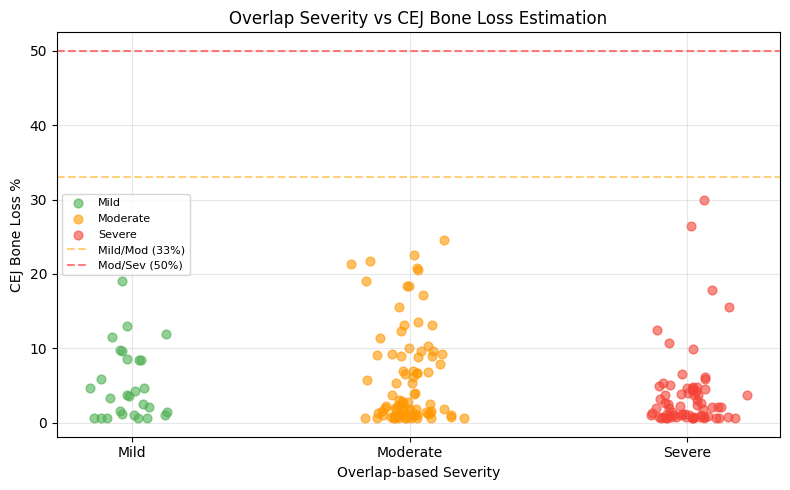

In [12]:
CLASS_NAMES = ['Mild', 'Moderate', 'Severe']
sev_map = {'Mild': 0, 'Moderate': 1, 'Severe': 2}

# Use reliable results with known overlap severity
df_compare = df_ok[df_ok['overlap_severity'] >= 0].copy()

if len(df_compare) > 3:
    df_compare['cej_sev_int'] = df_compare['severity'].map(sev_map)

    exact_agree = (df_compare['overlap_severity'] == df_compare['cej_sev_int']).mean() * 100
    within_1 = (abs(df_compare['overlap_severity'] - df_compare['cej_sev_int']) <= 1).mean() * 100

    print(f"Agreement (v2 improved, reliable only):")
    print(f"  Samples compared: {len(df_compare)}")
    print(f"  Exact match:      {exact_agree:.1f}%")
    print(f"  Within ±1 class:  {within_1:.1f}%")

    # Cross-tab
    df_compare['overlap_name'] = df_compare['overlap_severity'].map(
        {0: 'Mild', 1: 'Moderate', 2: 'Severe'}
    )
    cross = pd.crosstab(
        df_compare['overlap_name'], df_compare['severity'],
        rownames=['Overlap-based'], colnames=['CEJ-based']
    )
    print(f"\n{cross}")

    # Scatter: overlap severity vs CEJ bone loss %
    fig, ax = plt.subplots(figsize=(8, 5))
    colors_map = {0: '#4CAF50', 1: '#FF9800', 2: '#F44336'}
    for ov_sev in [0, 1, 2]:
        subset = df_compare[df_compare['overlap_severity'] == ov_sev]
        ax.scatter(subset['overlap_severity'] + np.random.normal(0, 0.08, len(subset)),
                   subset['bone_loss_pct'],
                   c=colors_map[ov_sev], alpha=0.6, s=40,
                   label=CLASS_NAMES[ov_sev])

    ax.axhline(MILD_THRESHOLD, color='orange', ls='--', alpha=0.5, label='Mild/Mod (33%)')
    ax.axhline(MODERATE_THRESHOLD, color='red', ls='--', alpha=0.5, label='Mod/Sev (50%)')
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_xlabel('Overlap-based Severity')
    ax.set_ylabel('CEJ Bone Loss %')
    ax.set_title('Overlap Severity vs CEJ Bone Loss Estimation')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_DIR, 'cej_v2_agreement.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Not enough comparable samples for agreement analysis.")

---
## Cell 10 — Visual Examples (v2)

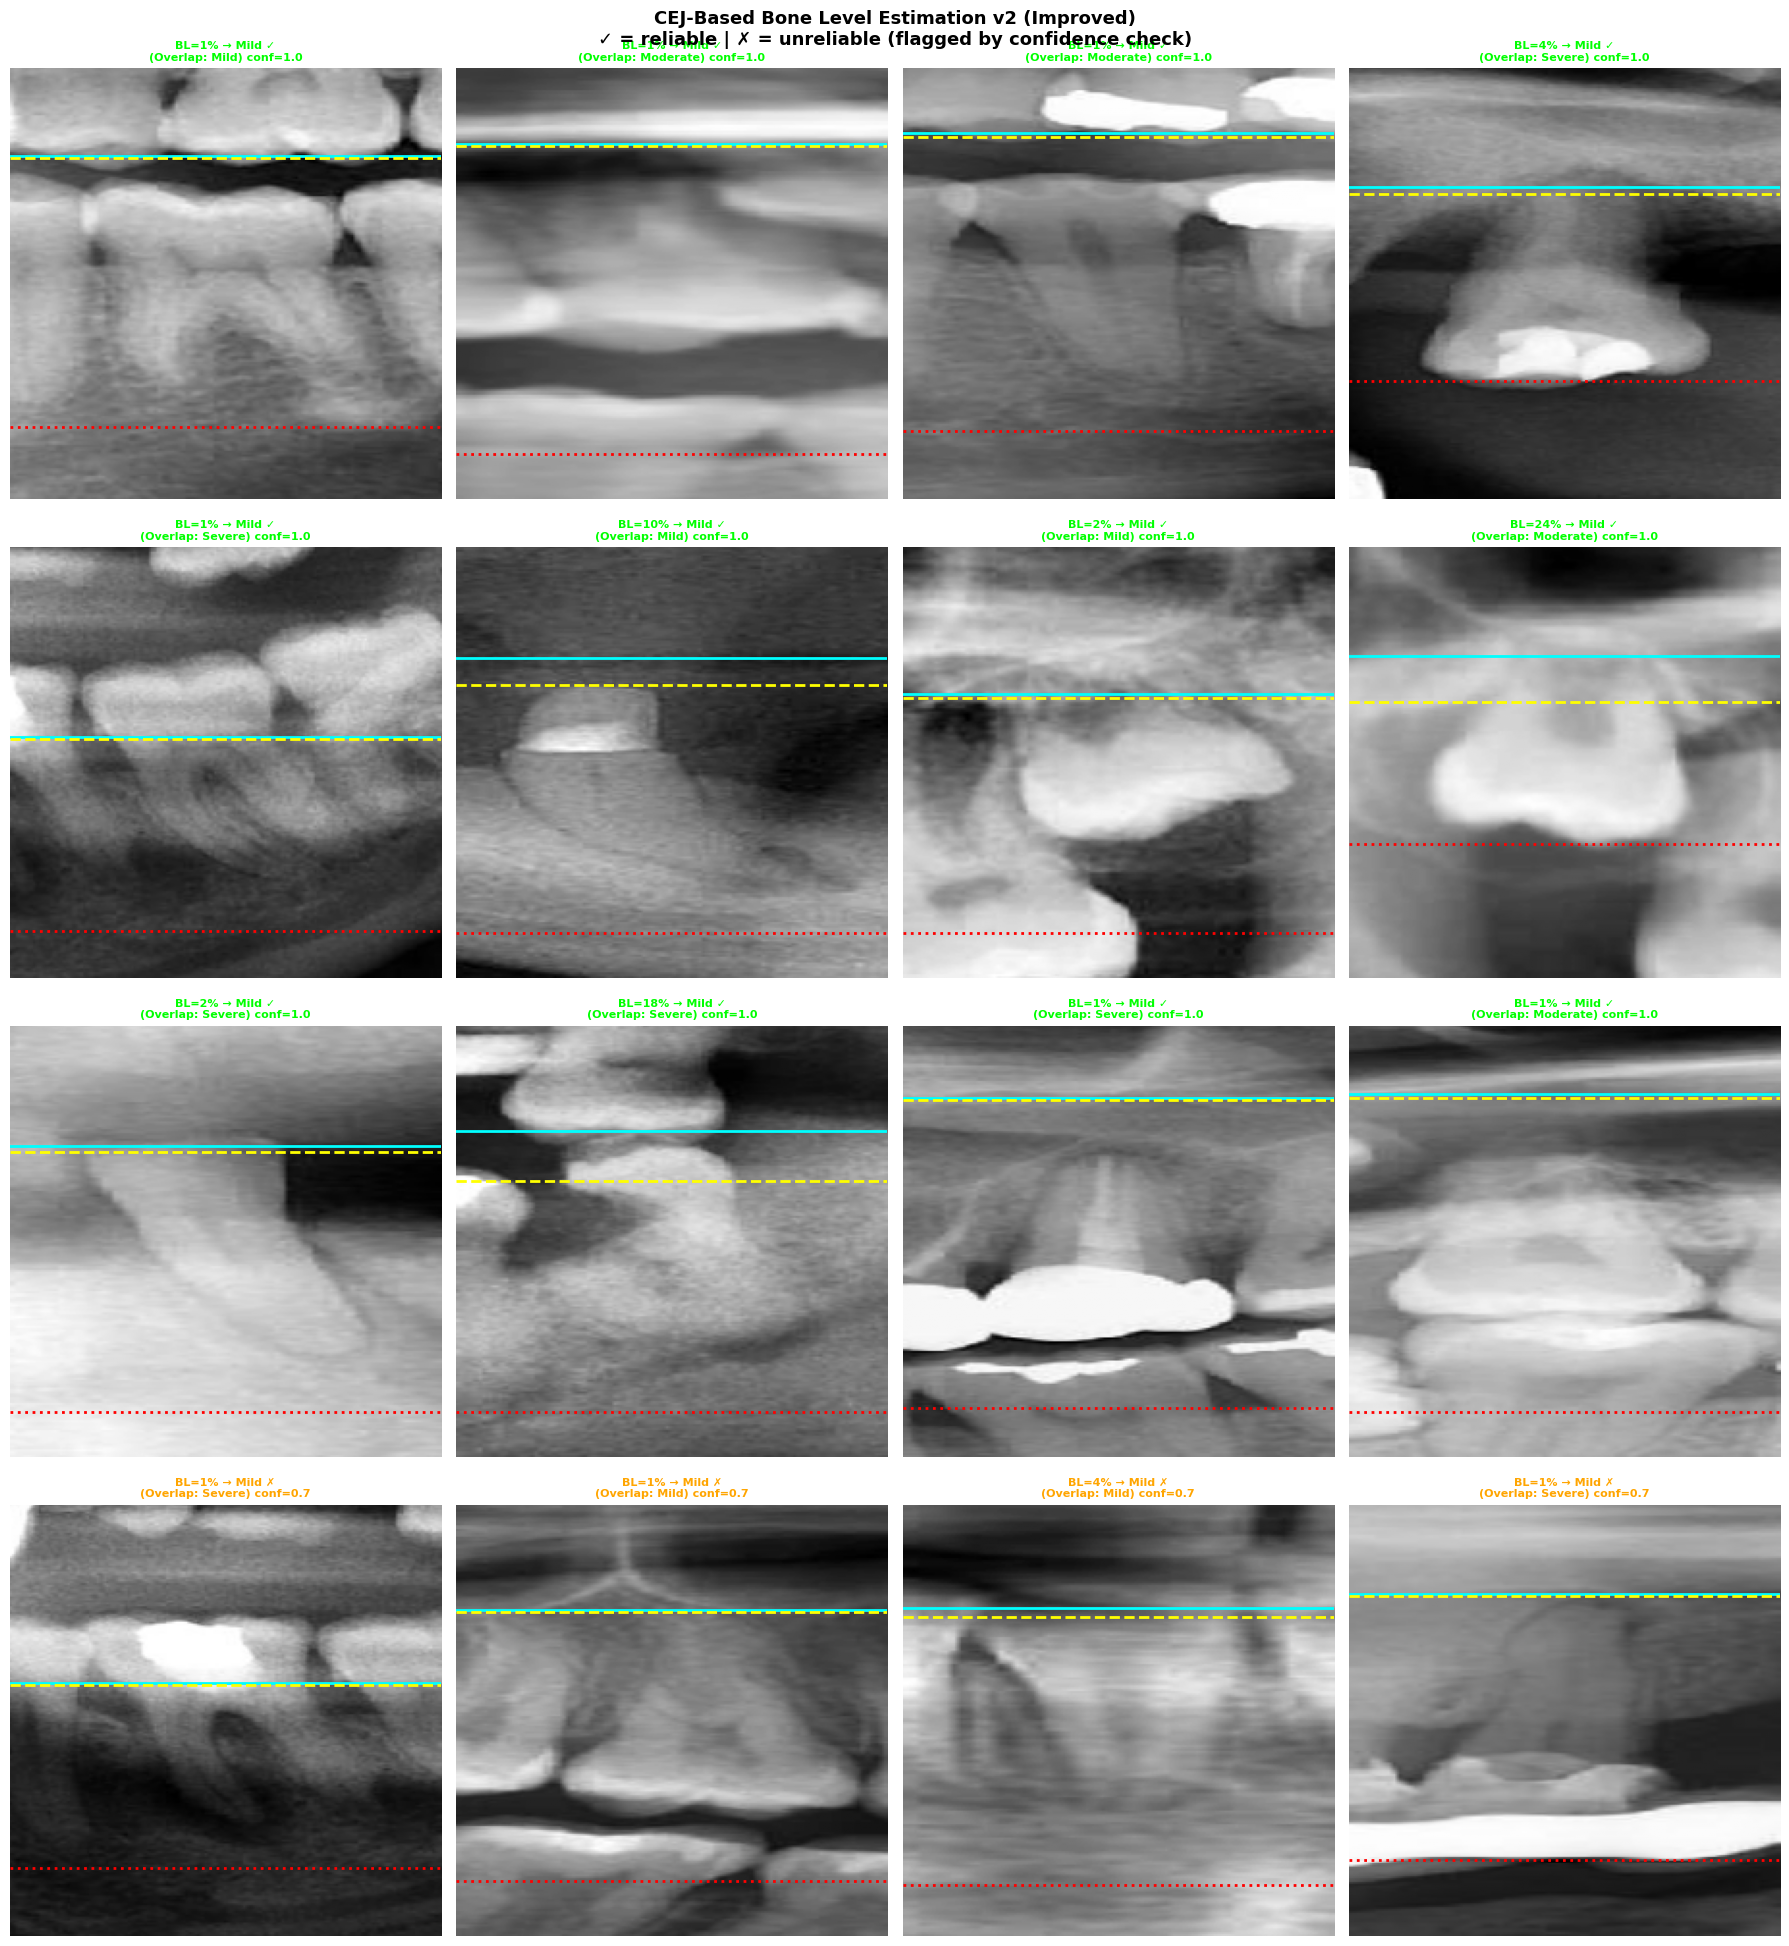

In [13]:
# Select samples: mix of reliable and unreliable, across severities
df_show = df_cej[df_cej['success']].copy()

n_show = min(16, len(df_show))
if len(df_show) > n_show:
    # Sample proportionally from reliable/unreliable
    reliable = df_show[df_show['is_reliable']]
    unreliable = df_show[~df_show['is_reliable']]
    n_rel = min(n_show * 3 // 4, len(reliable))
    n_unrel = min(n_show - n_rel, len(unreliable))
    samples = pd.concat([
        reliable.sample(n=n_rel, random_state=RANDOM_SEED) if n_rel > 0 else pd.DataFrame(),
        unreliable.sample(n=n_unrel, random_state=RANDOM_SEED) if n_unrel > 0 else pd.DataFrame(),
    ])
else:
    samples = df_show

n_cols = 4
n_rows = (len(samples) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5*n_cols, 5*n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)
axes = axes.flatten()

for i, (_, row) in enumerate(samples.iterrows()):
    if i >= len(axes):
        break

    ax = axes[i]

    # Load image
    img_path = None
    for split in ['train', 'val']:
        for cls in ['0', '1', '2']:
            p = os.path.join(SEVERITY_DIR, split, cls, row['filename'])
            if os.path.exists(p):
                img_path = p
                break
        if img_path:
            break

    if img_path is None:
        ax.axis('off')
        continue

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap='gray')

    # Draw landmarks
    ax.axhline(row['cej_y'], color='cyan', lw=2, ls='-')
    ax.axhline(row['crest_y'], color='yellow', lw=2, ls='--')
    ax.axhline(row['apex_y'], color='red', lw=2, ls=':')

    # Title
    rel_tag = '✓' if row['is_reliable'] else '✗'
    conf = row['confidence']
    title_color = 'lime' if row['is_reliable'] else 'orange'

    overlap_name = CLASS_NAMES[row['overlap_severity']] if row['overlap_severity'] >= 0 else '?'

    ax.set_title(
        f"BL={row['bone_loss_pct']:.0f}% → {row['severity']} {rel_tag}\n"
        f"(Overlap: {overlap_name}) conf={conf}",
        fontsize=8, fontweight='bold', color=title_color
    )
    ax.axis('off')

# Hide unused
for j in range(len(samples), len(axes)):
    axes[j].axis('off')

# Legend
legend_elements = [
    mpatches.Patch(color='cyan', label='CEJ'),
    mpatches.Patch(color='yellow', label='Bone Crest'),
    mpatches.Patch(color='red', label='Root Apex'),
]

plt.suptitle(
    'CEJ-Based Bone Level Estimation v2 (Improved)\n'
    '✓ = reliable | ✗ = unreliable (flagged by confidence check)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'cej_v2_examples.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 11 — Summary

In [14]:
# Compute final stats
n_total = len(df_cej)
n_success = int(df_cej['success'].sum())
n_reliable = int(df_cej[df_cej['success']]['is_reliable'].sum()) if n_success > 0 else 0
success_rate = n_success / n_total * 100 if n_total > 0 else 0
reliable_rate = n_reliable / n_total * 100 if n_total > 0 else 0

# Agreement
exact_agree_str = "N/A"
within1_str = "N/A"
if 'df_compare' in dir() and len(df_compare) > 0:
    exact_agree_str = f"{exact_agree:.1f}%"
    within1_str = f"{within_1:.1f}%"

# Reliable bone loss stats
bl_stats = ""
if len(df_ok) > 0:
    bl_stats = (f"Min={df_ok['bone_loss_pct'].min():.0f}%, "
                f"Median={df_ok['bone_loss_pct'].median():.0f}%, "
                f"Mean={df_ok['bone_loss_pct'].mean():.0f}%, "
                f"Max={df_ok['bone_loss_pct'].max():.0f}%")

summary = f"""
{'='*65}
 CEJ-BASED BONE LEVEL ESTIMATION — v2 IMPROVED SUMMARY
{'='*65}

{'—'*65}
 IMPROVEMENTS OVER v1
{'—'*65}
  1. CLAHE preprocessing (adaptive contrast normalization)
  2. Column-wise CEJ detection with median (robust to noise/tilt)
  3. Column-wise apex detection (handles curved/cropped roots)
  4. Focused bone crest search (CEJ to CEJ+40% root, not full crop)
  5. IQR outlier removal on crest estimates
  6. Confidence scoring (flags unreliable estimates)
  7. Tooth region isolation (trims top/bottom 10%)

{'—'*65}
 RESULTS
{'—'*65}
  Total crops analyzed: {n_total}
  Successful:           {n_success} ({success_rate:.1f}%)
  Reliable:             {n_reliable} ({reliable_rate:.1f}%)
  Failed:               {n_total - n_success}

  Bone loss % (reliable): {bl_stats}

  Agreement with overlap-based severity:
    Exact match:   {exact_agree_str}
    Within ±1:     {within1_str}

{'—'*65}
 DOCUMENTED LIMITATIONS
{'—'*65}
  - OPG panoramic projection causes overlapping anatomical structures
  - Teeth with crowns/large restorations disrupt intensity profiles
  - Anterior teeth have different morphology than posterior (thinner roots)
  - Background intensity varies across the OPG field
  - Heuristic approach — no learned features, relies on intensity gradients

{'—'*65}
 CLINICAL CONTEXT
{'—'*65}
  CEJ-based measurement is the clinical gold standard for bone loss
  assessment, but it is typically performed on periapical radiographs
  (high-resolution, single-tooth views), not on panoramic OPGs.

  Our results confirm that OPG-based CEJ estimation is feasible but
  inherently limited by image quality and projection geometry.
  The confidence scoring system identifies which estimates are
  trustworthy vs which should be flagged for manual review.

{'—'*65}
 PANEL NARRATIVE (UPDATED)
{'—'*65}
  "We implemented an improved CEJ-based bone level estimation using
   column-wise landmark detection with CLAHE preprocessing, focused
   bone crest search, and confidence scoring.

   The method achieves {success_rate:.0f}% detection rate with {reliable_rate:.0f}% classified
   as reliable. Agreement with overlap-based severity is {exact_agree_str}
   (exact) and {within1_str} (within ±1 class).

   While CEJ estimation is the clinical gold standard, it is designed
   for periapical radiographs, not OPGs. Our confidence scoring system
   identifies trustworthy estimates, making the approach viable as a
   clinical decision support tool when used alongside the primary
   overlap-based severity model (F1 macro = 0.72)."

{'='*65}
"""

print(summary)

# Save
summary_path = os.path.join(MODEL_DIR, 'cej_v2_summary.txt')
with open(summary_path, 'w') as f:
    f.write(summary)
print(f"Summary saved: {summary_path}")


 CEJ-BASED BONE LEVEL ESTIMATION — v2 IMPROVED SUMMARY

—————————————————————————————————————————————————————————————————
 IMPROVEMENTS OVER v1
—————————————————————————————————————————————————————————————————
  1. CLAHE preprocessing (adaptive contrast normalization)
  2. Column-wise CEJ detection with median (robust to noise/tilt)
  3. Column-wise apex detection (handles curved/cropped roots)
  4. Focused bone crest search (CEJ to CEJ+40% root, not full crop)
  5. IQR outlier removal on crest estimates
  6. Confidence scoring (flags unreliable estimates)
  7. Tooth region isolation (trims top/bottom 10%)

—————————————————————————————————————————————————————————————————
 RESULTS
—————————————————————————————————————————————————————————————————
  Total crops analyzed: 296
  Successful:           296 (100.0%)
  Reliable:             185 (62.5%)
  Failed:               0

  Bone loss % (reliable): Min=1%, Median=2%, Mean=5%, Max=30%

  Agreement with overlap-based severity:
    Exact m